
# DS605 Lab Assignment 8
## Decision Trees and Support Vector Machines

**Objective:** Implement Decision Tree and Linear SVM classifiers from scratch, visualize their decision boundaries, compare them with Scikit-learn, and explore nonlinear SVM kernels.

**Dataset:** UCI Banknote Authentication Dataset

**Parts:**
- Part A: Decision Tree from Scratch
- Part B: Linear SVM from Scratch
- Part C: Kernel SVM and Nonlinear Boundaries
- Part D: Final Model Comparison



## 1. Import Libraries

Import the libraries required for data handling, numerical computation, visualization, model evaluation, and execution-time measurement.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.



## 2. Load the Banknote Authentication Dataset

The dataset contains 1,372 samples, four numerical features, and a binary class label.

The features are:
- Variance
- Skewness
- Curtosis
- Entropy

The target column represents the banknote class.


In [2]:
from pathlib import Path

column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

file_path = Path(
    r"C:\Users\HP\Documents\DS605-Fundamentals-of-Machine-Learning\LAB08\data_banknote_authentication.txt"
)

if not file_path.is_file():
    raise FileNotFoundError(
        f"Dataset not found at: {file_path}\n"
        "Check that the file exists and the path is correct."
    )

df = pd.read_csv(
    file_path,
    header=None,
    names=column_names,
    dtype={
        "variance": "float64",
        "skewness": "float64",
        "curtosis": "float64",
        "entropy": "float64",
        "class": "int8"
    }
)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")

display(df.head())

print("\nDataset information:")
df.info()

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

print("\nMissing values:")
print(df.isna().sum())

Dataset loaded successfully!
Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int8   
dtypes: float64(4), int8(1)
memory usage: 44.3 KB

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64



## 3. Exploratory Data Analysis

Examine the statistical summaries and distributions of the four features. Visualize the target class distribution to understand the dataset before training the classifiers.


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495


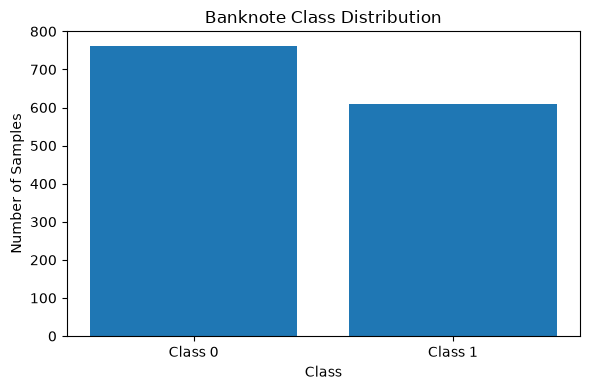

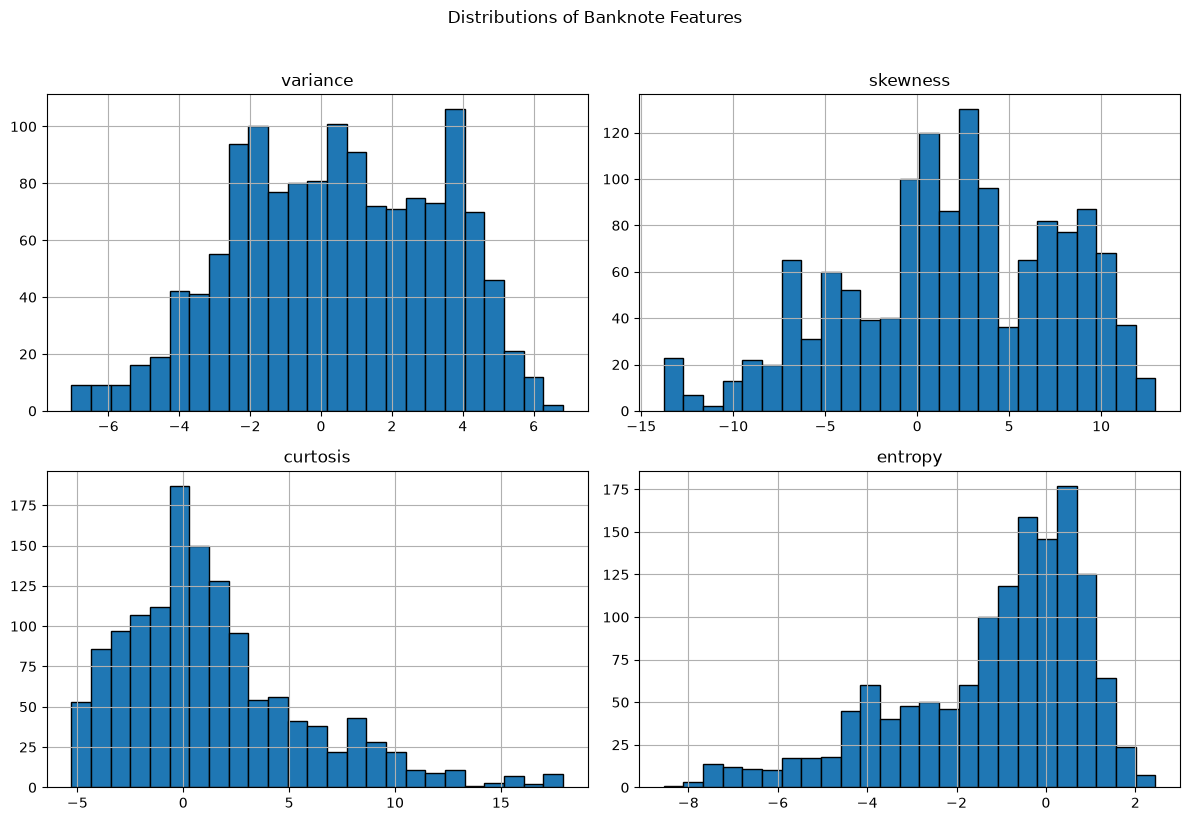

In [3]:

# Statistical summary of the four input features
display(df.iloc[:, :4].describe().T)

# Plot class distribution
class_counts = df["class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Banknote Class Distribution")
plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.tight_layout()
plt.show()

# Plot distributions of all four features
df.iloc[:, :4].hist(
    figsize=(12, 8),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distributions of Banknote Features", y=1.02)
plt.tight_layout()
plt.show()



## 4. Train-Test Split and Feature Selection

Split the dataset into training and testing sets using an 80:20 ratio. Use stratification to preserve the class proportions in both sets.

For two-dimensional decision-boundary visualizations, select variance and skewness. Retain all four features for the final model comparison.


In [4]:

# Separate all four features and the target
X_all = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

# Consistent train-test split for the entire assignment
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Select two features for 2D visualizations
feature_names_2d = ["variance", "skewness"]
feature_indices_2d = [0, 1]

X_train_2d = X_train_all[:, feature_indices_2d]
X_test_2d = X_test_all[:, feature_indices_2d]

print("Full training set:", X_train_all.shape)
print("Full testing set:", X_test_all.shape)
print("2D training set:", X_train_2d.shape)
print("2D testing set:", X_test_2d.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())


Full training set: (1097, 4)
Full testing set: (275, 4)
2D training set: (1097, 2)
2D testing set: (275, 2)

Training class distribution:
0    609
1    488
Name: count, dtype: int64

Testing class distribution:
0    153
1    122
Name: count, dtype: int64



## Part A: Decision Tree from Scratch

### 5. Implementing Gini Impurity and Entropy

Gini impurity and entropy measure the class impurity of a node. They will be used to evaluate candidate feature-threshold splits.

- Gini impurity: measures the probability of incorrectly classifying a randomly selected sample if its class is assigned according to the node's class distribution.
- Entropy: measures the uncertainty in the class distribution.

A good split reduces the weighted impurity of the child nodes compared with the parent node.


In [6]:

def gini_impurity(y_node):
    """
    Calculate Gini impurity for a node.
    """
    if len(y_node) == 0:
        return 0.0

    _, counts = np.unique(y_node, return_counts=True)
    probabilities = counts / len(y_node)

    return 1.0 - np.sum(probabilities ** 2)


def entropy_impurity(y_node):
    """
    Calculate entropy for a node.
    """
    if len(y_node) == 0:
        return 0.0

    _, counts = np.unique(y_node, return_counts=True)
    probabilities = counts / len(y_node)

    return -np.sum(probabilities * np.log2(probabilities))


def weighted_child_impurity(y_left, y_right, criterion="gini"):
    """
    Calculate weighted impurity after a split.
    """
    total_samples = len(y_left) + len(y_right)

    if total_samples == 0:
        return 0.0

    impurity_function = (
        gini_impurity if criterion == "gini"
        else entropy_impurity
    )

    left_weight = len(y_left) / total_samples
    right_weight = len(y_right) / total_samples

    return (
        left_weight * impurity_function(y_left)
        + right_weight * impurity_function(y_right)
    )


# Test the impurity functions
test_labels = np.array([0, 0, 1, 1])

print("Gini impurity:", gini_impurity(test_labels))
print("Entropy:", entropy_impurity(test_labels))

pure_labels = np.array([1, 1, 1, 1])

print("\nGini impurity (pure node):", gini_impurity(pure_labels))
print("Entropy (pure node):", entropy_impurity(pure_labels))


Gini impurity: 0.5
Entropy: 1.0

Gini impurity (pure node): 0.0
Entropy (pure node): -0.0



### 6. Finding the Best Split

For each feature, evaluate candidate thresholds between consecutive sorted, unique feature values. Divide the samples into left and right groups, calculate the weighted impurity, and select the split with the lowest impurity.

The information gain is the parent impurity minus the weighted child impurity.


In [20]:

def find_best_split(X_node, y_node, criterion="gini"):
    """
    Find the feature and threshold with the lowest weighted
    child impurity.

    Returns:
        best_feature, best_threshold, best_impurity
    """
    n_samples, n_features = X_node.shape

    if n_samples < 2:
        return None, None, None

    impurity_function = (
        gini_impurity if criterion == "gini"
        else entropy_impurity
    )

    best_feature = None
    best_threshold = None
    best_impurity = float("inf")

    for feature_idx in range(n_features):
        values = np.unique(X_node[:, feature_idx])

        if len(values) < 2:
            continue

        # Midpoints between consecutive unique values
        thresholds = (values[:-1] + values[1:]) / 2.0

        for threshold in thresholds:
            left_mask = X_node[:, feature_idx] <= threshold
            right_mask = ~left_mask

            y_left = y_node[left_mask]
            y_right = y_node[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            split_impurity = weighted_child_impurity(
                y_left, y_right, criterion
            )

            if split_impurity < best_impurity:
                best_impurity = split_impurity
                best_feature = feature_idx
                best_threshold = threshold

    return best_feature, best_threshold, best_impurity


# Test the split function on a small example
X_example = np.array([
    [1.0],
    [2.0],
    [3.0],
    [4.0]
])

y_example = np.array([0, 0, 1, 1])

feature, threshold, impurity = find_best_split(
    X_example,
    y_example,
    criterion="gini"
)

print("Best feature index:", feature)
print("Best threshold:", threshold)
print("Weighted child impurity:", impurity)
print("Parent Gini impurity:", gini_impurity(y_example))
print("Information gain:",
      gini_impurity(y_example) - impurity)


Best feature index: 0
Best threshold: 2.5
Weighted child impurity: 0.0
Parent Gini impurity: 0.5
Information gain: 0.5



### 7. Recursive Decision Tree Construction

Implement a manual Decision Tree classifier using recursive splitting. The tree uses the selected impurity criterion and stopping conditions to prevent unlimited growth.


In [21]:

class ManualDecisionTree:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None
        self.n_features_in_ = None

    def _majority_class(self, y_node):
        classes, counts = np.unique(y_node, return_counts=True)
        return classes[np.argmax(counts)]

    def _build_tree(self, X_node, y_node, depth):
        node = {
            "prediction": self._majority_class(y_node),
            "samples": len(y_node),
            "impurity": (
                gini_impurity(y_node)
                if self.criterion == "gini"
                else entropy_impurity(y_node)
            ),
            "feature": None,
            "threshold": None,
            "left": None,
            "right": None
        }

        # Stopping conditions
        if (
            node["impurity"] == 0
            or depth >= self.max_depth
            or len(y_node) < self.min_samples_split
        ):
            return node

        feature, threshold, child_impurity = find_best_split(
            X_node, y_node, self.criterion
        )

        if feature is None:
            return node

        left_mask = X_node[:, feature] <= threshold
        right_mask = ~left_mask

        # Enforce minimum leaf size
        if (
            np.sum(left_mask) < self.min_samples_leaf
            or np.sum(right_mask) < self.min_samples_leaf
        ):
            return node

        node["feature"] = feature
        node["threshold"] = threshold
        node["information_gain"] = node["impurity"] - child_impurity

        node["left"] = self._build_tree(
            X_node[left_mask], y_node[left_mask], depth + 1
        )
        node["right"] = self._build_tree(
            X_node[right_mask], y_node[right_mask], depth + 1
        )

        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.n_features_in_ = X.shape[1]
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        # Leaf node
        if node["feature"] is None:
            return node["prediction"]

        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])
        else:
            return self._predict_one(x, node["right"])

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        return np.array([
            self._predict_one(x, self.root) for x in X
        ])

    def print_tree(self, node=None, depth=0, feature_names=None):
        if node is None:
            node = self.root

        indent = "  " * depth

        if node["feature"] is None:
            print(
                f"{indent}Leaf: predict={node['prediction']}, "
                f"samples={node['samples']}"
            )
            return

        feature_name = (
            feature_names[node["feature"]]
            if feature_names is not None
            else f"X[{node['feature']}]"
        )

        print(
            f"{indent}if {feature_name} <= "
            f"{node['threshold']:.4f}: "
            f"(samples={node['samples']}, "
            f"gain={node.get('information_gain', 0):.4f})"
        )

        self.print_tree(node["left"], depth + 1, feature_names)

        print(f"{indent}else:")

        self.print_tree(node["right"], depth + 1, feature_names)



### 8. Training and Evaluating the Manual Decision Tree

Train the manually implemented classifier using the two selected features. Evaluate its predictions on the held-out test set using accuracy, precision, recall, and F1-score.


In [22]:

manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

tree_start = time.perf_counter()

manual_tree.fit(X_train_2d, y_train)

tree_train_time = time.perf_counter() - tree_start

predict_start = time.perf_counter()

y_pred_manual_tree = manual_tree.predict(X_test_2d)

tree_predict_time = time.perf_counter() - predict_start

print("Manual Decision Tree Results (2 features)")
print("-----------------------------------------")
print("Accuracy:",
      accuracy_score(y_test, y_pred_manual_tree))
print("Precision:",
      precision_score(y_test, y_pred_manual_tree, zero_division=0))
print("Recall:",
      recall_score(y_test, y_pred_manual_tree, zero_division=0))
print("F1-score:",
      f1_score(y_test, y_pred_manual_tree, zero_division=0))
print("Training time:", round(tree_train_time, 4), "seconds")
print("Prediction time:", round(tree_predict_time, 6), "seconds")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_manual_tree, zero_division=0))

print("\nLearned Tree Rules:")
manual_tree.print_tree(feature_names=feature_names_2d)


Manual Decision Tree Results (2 features)
-----------------------------------------
Accuracy: 0.9309090909090909
Precision: 0.8814814814814815
Recall: 0.9754098360655737
F1-score: 0.9260700389105059
Training time: 0.4688 seconds
Prediction time: 0.00046 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94       153
           1       0.88      0.98      0.93       122

    accuracy                           0.93       275
   macro avg       0.93      0.94      0.93       275
weighted avg       0.94      0.93      0.93       275


Learned Tree Rules:
if variance <= 0.7651: (samples=1097, gain=0.2421)
  if skewness <= 5.1608: (samples=593, gain=0.1489)
    if variance <= 0.3202: (samples=464, gain=0.0287)
      if variance <= -0.4586: (samples=413, gain=0.0052)
        if skewness <= 0.0548: (samples=346, gain=0.0020)
          Leaf: predict=1, samples=208
        else:
          Leaf: predict=1, samples=138
  


### 9. Visualizing the Manually Learned Decision Tree

Visualize the tree structure, including its feature-threshold rules and predicted classes at leaf nodes. Limit the displayed depth for readability.


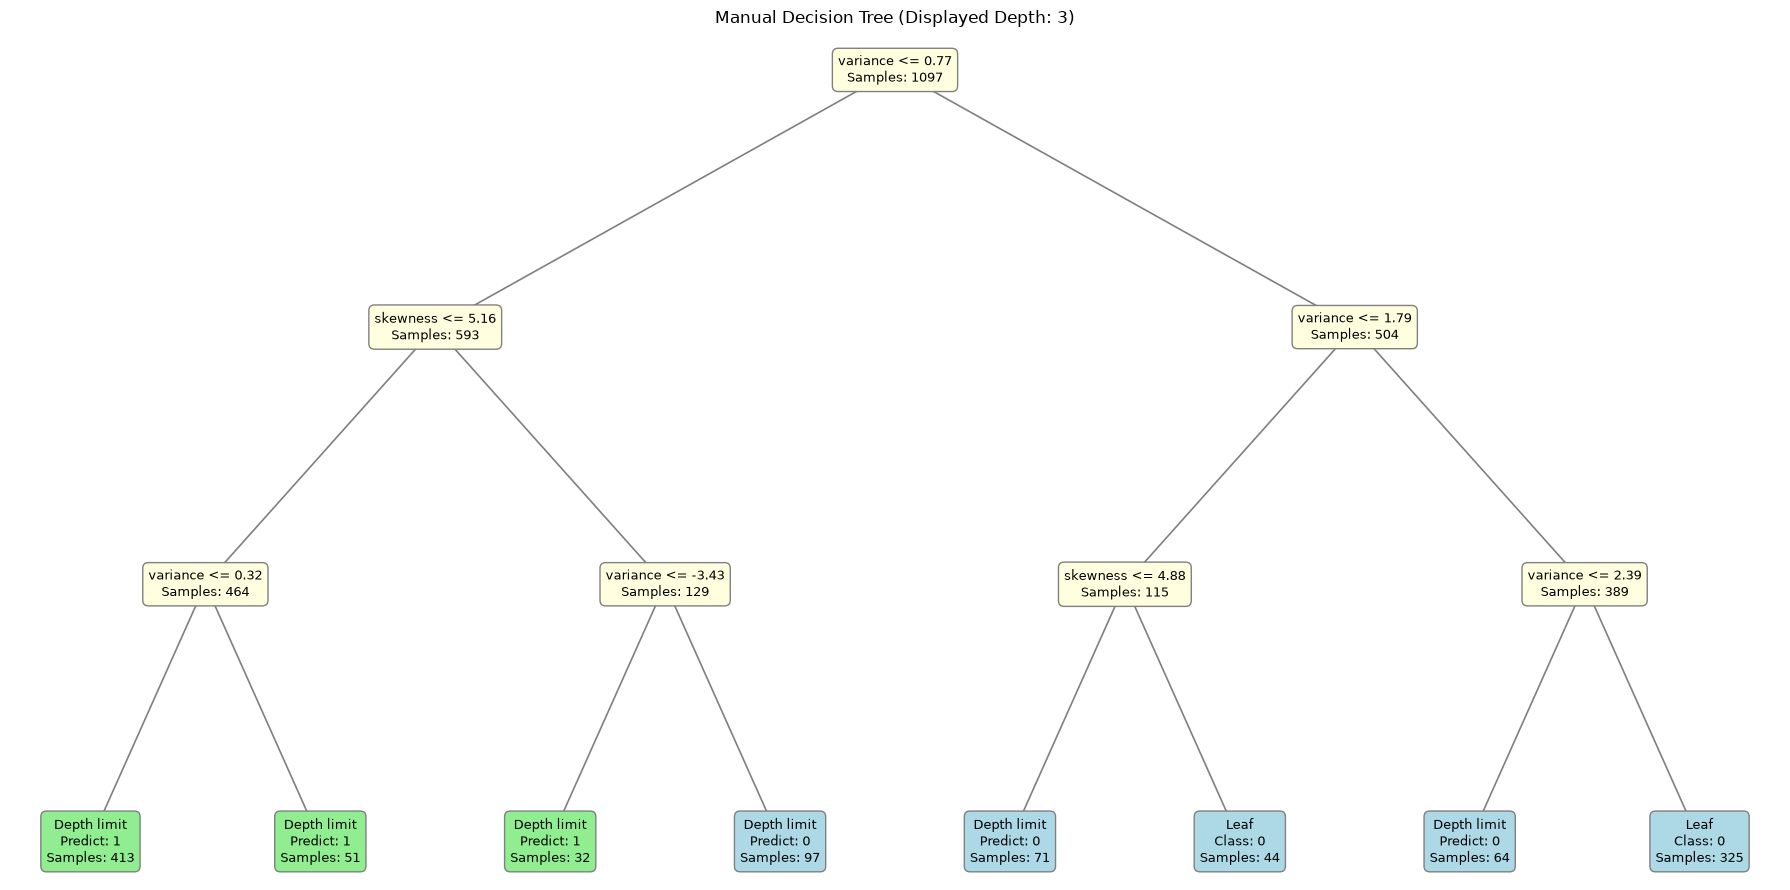

In [23]:

def plot_manual_tree(tree, feature_names, max_display_depth=3):
    fig, ax = plt.subplots(figsize=(18, 9))
    leaf_positions = [0]

    def count_leaves(node, depth):
        if node["feature"] is None or depth >= max_display_depth:
            return 1
        return (
            count_leaves(node["left"], depth + 1)
            + count_leaves(node["right"], depth + 1)
        )

    def draw_node(node, depth, x_left, x_right, parent_x=None, parent_y=None):
        x = (x_left + x_right) / 2
        y_pos = -depth

        if parent_x is not None:
            ax.plot([parent_x, x], [parent_y, y_pos],
                    color="gray", linewidth=1.2)

        if node["feature"] is None or depth >= max_display_depth:
            if node["feature"] is None:
                label = f"Leaf\nClass: {node['prediction']}\nSamples: {node['samples']}"
            else:
                label = (
                    f"Depth limit\nPredict: {node['prediction']}\n"
                    f"Samples: {node['samples']}"
                )
            color = "lightgreen" if node["prediction"] == 1 else "lightblue"
        else:
            label = (
                f"{feature_names[node['feature']]} <= "
                f"{node['threshold']:.2f}\n"
                f"Samples: {node['samples']}"
            )
            color = "lightyellow"

        ax.text(
            x, y_pos, label,
            ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.45",
                      facecolor=color, edgecolor="gray")
        )

        if node["feature"] is not None and depth < max_display_depth:
            left_leaves = count_leaves(node["left"], depth + 1)
            right_leaves = count_leaves(node["right"], depth + 1)
            total = left_leaves + right_leaves
            split_x = x_left + (x_right - x_left) * left_leaves / total

            draw_node(
                node["left"], depth + 1,
                x_left, split_x, x, y_pos
            )
            draw_node(
                node["right"], depth + 1,
                split_x, x_right, x, y_pos
            )

    total_leaves = count_leaves(tree.root, 0)
    draw_node(tree.root, 0, 0, total_leaves)

    ax.set_title("Manual Decision Tree (Displayed Depth: 3)")
    ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_manual_tree(manual_tree, feature_names_2d, max_display_depth=3)



### 10. Decision Boundary of the Manual Decision Tree

Plot the classification regions learned from variance and skewness. Overlay the test samples to show how the model separates the two classes.


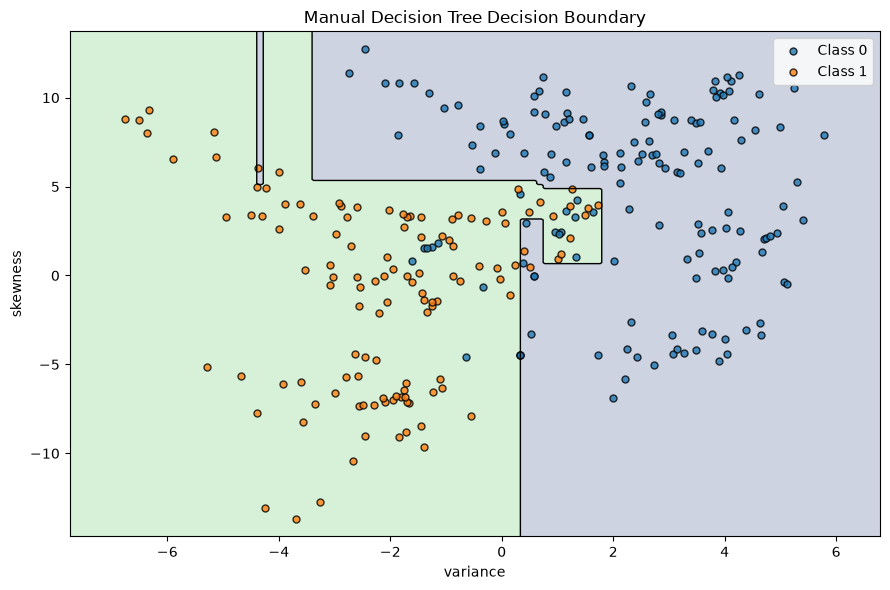

In [24]:

def plot_decision_boundary_2d(model, X, y, title, feature_names):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, levels=[-0.5, 0.5, 1.5])
    plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1)

    for class_label in np.unique(y):
        mask = y == class_label
        plt.scatter(
            X[mask, 0], X[mask, 1],
            label=f"Class {class_label}",
            edgecolors="black", s=25, alpha=0.8
        )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_decision_boundary_2d(
    manual_tree,
    X_test_2d,
    y_test,
    "Manual Decision Tree Decision Boundary",
    feature_names_2d
)



### 11. Scikit-learn Decision Tree Comparison

Train a Scikit-learn Decision Tree using the same training samples, features, criterion, and maximum depth. Compare its test performance with the manual implementation.


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9309,0.8815,0.9754,0.9261,0.4688,0.0005
1,Scikit-learn Decision Tree,0.9309,0.8815,0.9754,0.9261,0.0027,0.0003


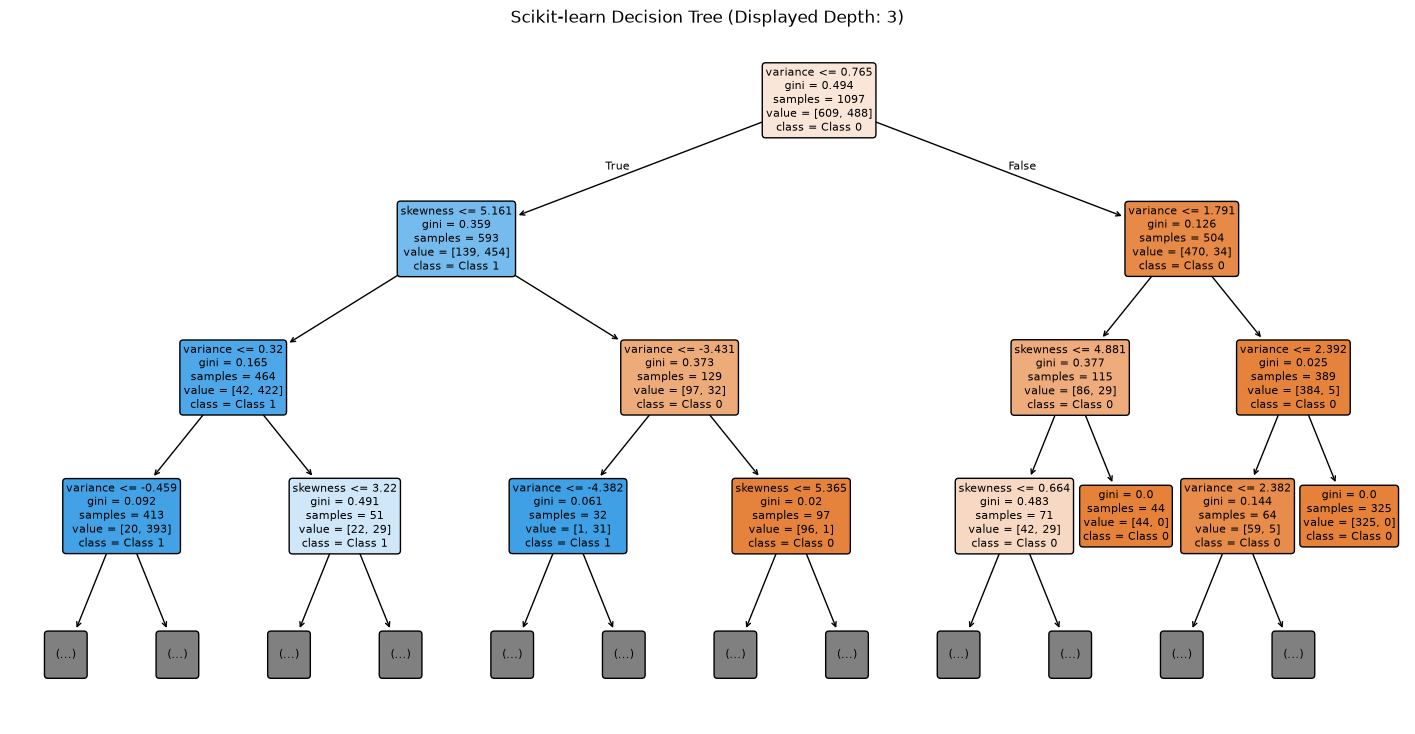

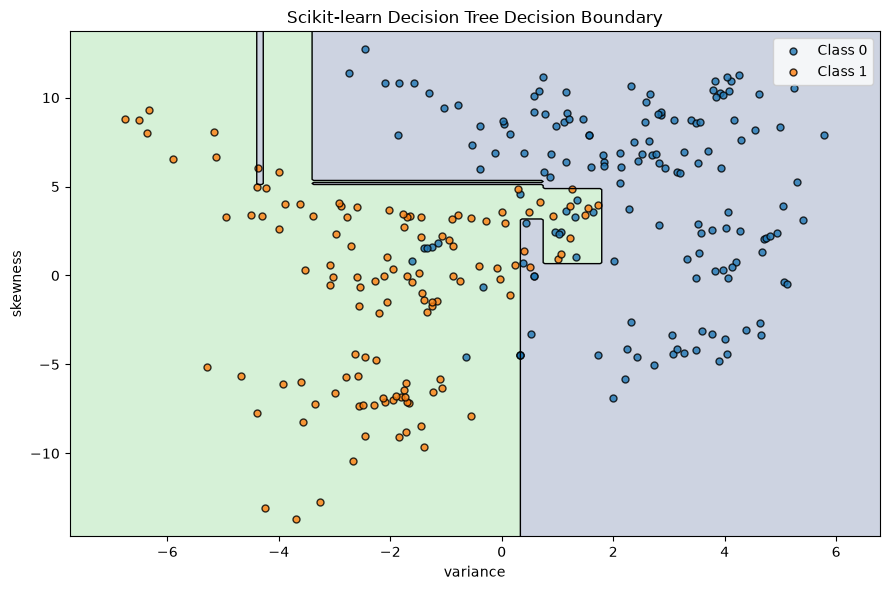

In [25]:

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

sk_tree_start = time.perf_counter()
sklearn_tree.fit(X_train_2d, y_train)
sk_tree_train_time = time.perf_counter() - sk_tree_start

sk_tree_predict_start = time.perf_counter()
y_pred_sklearn_tree = sklearn_tree.predict(X_test_2d)
sk_tree_predict_time = time.perf_counter() - sk_tree_predict_start

tree_comparison = pd.DataFrame({
    "Model": ["Manual Decision Tree", "Scikit-learn Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_manual_tree),
        accuracy_score(y_test, y_pred_sklearn_tree)
    ],
    "Precision": [
        precision_score(y_test, y_pred_manual_tree, zero_division=0),
        precision_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_manual_tree, zero_division=0),
        recall_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_manual_tree, zero_division=0),
        f1_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "Training Time (s)": [tree_train_time, sk_tree_train_time],
    "Prediction Time (s)": [tree_predict_time, sk_tree_predict_time]
})

display(tree_comparison.round(4))

# Visualize the Scikit-learn tree
plt.figure(figsize=(18, 9))
plot_tree(
    sklearn_tree,
    feature_names=feature_names_2d,
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Scikit-learn Decision Tree (Displayed Depth: 3)")
plt.show()

plot_decision_boundary_2d(
    sklearn_tree,
    X_test_2d,
    y_test,
    "Scikit-learn Decision Tree Decision Boundary",
    feature_names_2d
)



### 12. Effect of Criterion and Maximum Depth

Compare manually implemented and Scikit-learn Decision Trees using Gini impurity and entropy at different maximum depths. Record test accuracy, F1-score, training time, and prediction agreement between the two implementations.


In [26]:

depth_values = [2, 3, 5]
criterion_values = ["gini", "entropy"]

depth_criterion_results = []

for criterion_name in criterion_values:
    for depth_value in depth_values:

        # Manual Decision Tree
        manual_model = ManualDecisionTree(
            criterion=criterion_name,
            max_depth=depth_value
        )

        start = time.perf_counter()
        manual_model.fit(X_train_2d, y_train)
        manual_fit_time = time.perf_counter() - start

        start = time.perf_counter()
        manual_predictions = manual_model.predict(X_test_2d)
        manual_pred_time = time.perf_counter() - start

        # Scikit-learn Decision Tree
        sklearn_model = DecisionTreeClassifier(
            criterion=criterion_name,
            max_depth=depth_value,
            random_state=42
        )

        start = time.perf_counter()
        sklearn_model.fit(X_train_2d, y_train)
        sklearn_fit_time = time.perf_counter() - start

        start = time.perf_counter()
        sklearn_predictions = sklearn_model.predict(X_test_2d)
        sklearn_pred_time = time.perf_counter() - start

        depth_criterion_results.append({
            "Criterion": criterion_name,
            "Max Depth": depth_value,
            "Manual Accuracy": accuracy_score(
                y_test, manual_predictions
            ),
            "Sklearn Accuracy": accuracy_score(
                y_test, sklearn_predictions
            ),
            "Manual F1": f1_score(
                y_test, manual_predictions, zero_division=0
            ),
            "Sklearn F1": f1_score(
                y_test, sklearn_predictions, zero_division=0
            ),
            "Prediction Agreement": np.mean(
                manual_predictions == sklearn_predictions
            ),
            "Manual Train (s)": manual_fit_time,
            "Sklearn Train (s)": sklearn_fit_time,
            "Manual Predict (s)": manual_pred_time,
            "Sklearn Predict (s)": sklearn_pred_time
        })

depth_criterion_df = pd.DataFrame(depth_criterion_results)

display(depth_criterion_df.round(4))


,Criterion,Max Depth,Manual Accuracy,Sklearn Accuracy,Manual F1,Sklearn F1,Prediction Agreement,Manual Train (s),Sklearn Train (s),Manual Predict (s),Sklearn Predict (s)
0,gini,2,0.8764,0.8764,0.8595,0.8595,1.0,0.2365,0.0019,0.0002,0.0002
1,gini,3,0.9091,0.9091,0.9004,0.9004,1.0,0.3357,0.0021,0.0003,0.0002
2,gini,5,0.9309,0.9309,0.9261,0.9261,1.0,0.5029,0.0024,0.0004,0.0003
3,entropy,2,0.8764,0.8764,0.8595,0.8595,1.0,0.2394,0.0021,0.0002,0.0002
4,entropy,3,0.9091,0.9091,0.9004,0.9004,1.0,0.3078,0.0024,0.0003,0.0002
5,entropy,5,0.9345,0.9345,0.9286,0.9286,1.0,0.4190,0.0036,0.0004,0.0003



### Observations

Compare how the criterion and maximum depth affect test accuracy and F1-score. Deeper trees can capture more complex decision boundaries but may overfit the training data. Gini and entropy may select different splits, although they can sometimes produce similar predictions.



## Part B: Linear SVM from Scratch

### 13. Feature Scaling and Label Encoding

Scale variance and skewness using the mean and standard deviation calculated from the training set. Apply these same statistics to the test set.

Encode the binary labels as -1 and +1, as required for the hinge-loss formulation of a Support Vector Machine.


In [27]:

# Calculate scaling statistics using training data only
svm_mean = X_train_2d.mean(axis=0)
svm_std = X_train_2d.std(axis=0)

# Protect against division by zero
svm_std[svm_std == 0] = 1.0

X_train_svm = (X_train_2d - svm_mean) / svm_std
X_test_svm = (X_test_2d - svm_mean) / svm_std

# Map class 0 -> -1 and class 1 -> +1
y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

print("Training features shape:", X_train_svm.shape)
print("Testing features shape:", X_test_svm.shape)
print("Training labels:", np.unique(y_train_svm))
print("Testing labels:", np.unique(y_test_svm))
print("Training feature means:", X_train_svm.mean(axis=0).round(4))
print("Training feature standard deviations:",
      X_train_svm.std(axis=0).round(4))


Training features shape: (1097, 2)
Testing features shape: (275, 2)
Training labels: [-1  1]
Testing labels: [-1  1]
Training feature means: [-0.  0.]
Training feature standard deviations: [1. 1.]



### 14. Linear SVM Implementation Using NumPy

For each training sample, calculate the margin:

yᵢ(w · xᵢ + b)

Samples whose margin is below 1 contribute to the hinge loss. Update the weights and bias using subgradient descent.

The implementation will provide decision scores, predictions, and the loss history for monitoring convergence.


In [28]:

class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.001, n_iterations=5000):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features, dtype=float)
        self.bias = 0.0
        self.loss_history = []

        for iteration in range(self.n_iterations):
            margins = y * (X @ self.weights + self.bias)
            violating = margins < 1.0

            # Objective: 0.5 * ||w||^2 + C * mean(hinge loss)
            if np.any(violating):
                grad_w = (
                    self.weights
                    - self.C * np.mean(
                        (y[violating, None] * X[violating]),
                        axis=0
                    ) * (np.sum(violating) / n_samples)
                )

                grad_b = (
                    -self.C * np.sum(y[violating]) / n_samples
                )
            else:
                grad_w = self.weights.copy()
                grad_b = 0.0

            self.weights -= self.learning_rate * grad_w
            self.bias -= self.learning_rate * grad_b

            if iteration % 100 == 0 or iteration == self.n_iterations - 1:
                updated_margins = y * (
                    X @ self.weights + self.bias
                )
                hinge_loss = np.maximum(0, 1 - updated_margins).mean()
                objective = (
                    0.5 * np.dot(self.weights, self.weights)
                    + self.C * hinge_loss
                )
                self.loss_history.append(objective)

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.weights + self.bias

    def predict(self, X):
        scores = self.decision_function(X)
        # Convert SVM labels back to dataset labels 0 and 1
        return np.where(scores >= 0, 1, 0)



### 15. Training and Evaluating the Manual Linear SVM

Train the manually implemented SVM on the scaled two-feature training set. Evaluate accuracy, precision, recall, F1-score, training time, and prediction time on the test set.


Manual Linear SVM Results (2 features)
--------------------------------------
Accuracy: 0.8654545454545455
Precision: 0.912621359223301
Recall: 0.7704918032786885
F1-score: 0.8355555555555556
Training time: 0.543 seconds
Prediction time: 9e-05 seconds
Weights: [-0.502542   -0.25609766]
Bias: -0.26505742935276694


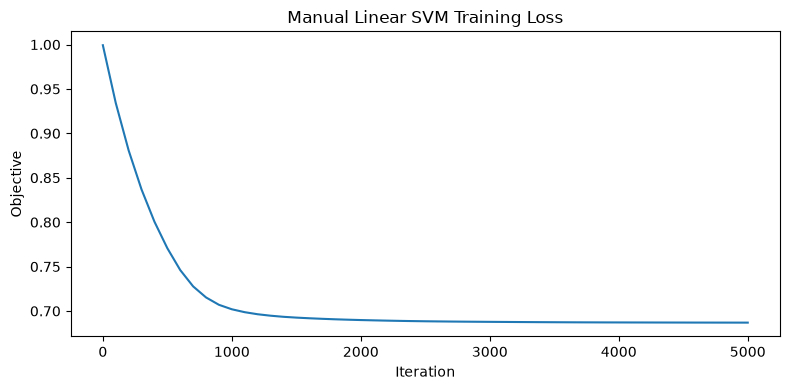

In [29]:

manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.001,
    n_iterations=5000
)

svm_train_start = time.perf_counter()
manual_svm.fit(X_train_svm, y_train_svm)
svm_train_time = time.perf_counter() - svm_train_start

svm_predict_start = time.perf_counter()
y_pred_manual_svm = manual_svm.predict(X_test_svm)
svm_predict_time = time.perf_counter() - svm_predict_start

print("Manual Linear SVM Results (2 features)")
print("--------------------------------------")
print("Accuracy:",
      accuracy_score(y_test, y_pred_manual_svm))
print("Precision:",
      precision_score(y_test, y_pred_manual_svm, zero_division=0))
print("Recall:",
      recall_score(y_test, y_pred_manual_svm, zero_division=0))
print("F1-score:",
      f1_score(y_test, y_pred_manual_svm, zero_division=0))
print("Training time:", round(svm_train_time, 4), "seconds")
print("Prediction time:", round(svm_predict_time, 6), "seconds")
print("Weights:", manual_svm.weights)
print("Bias:", manual_svm.bias)

plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(len(manual_svm.loss_history)) * 100,
    manual_svm.loss_history
)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("Manual Linear SVM Training Loss")
plt.tight_layout()
plt.show()



### 16. Visualizing the SVM Decision Boundary and Margins

Plot the decision boundary and the two margin lines using the learned weight vector and bias. Highlight test samples that violate the margin condition, including misclassified samples.


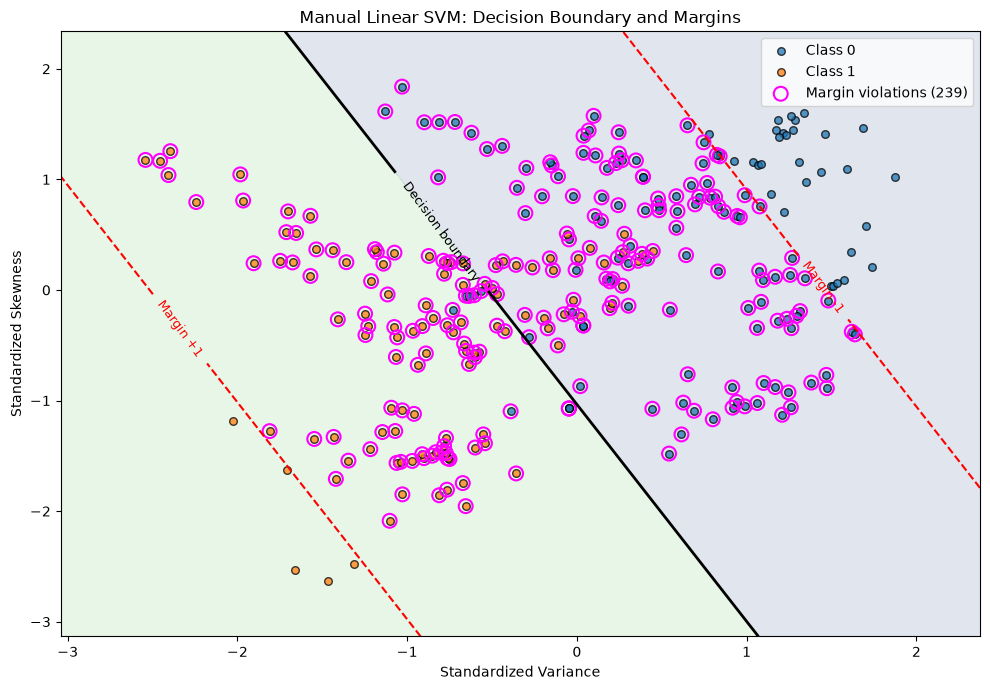

Number of margin-violating test samples: 239
Number of test samples: 275
Number of misclassified test samples: 37


In [30]:

# Generate a grid in the scaled feature space
svm_x_min = X_test_svm[:, 0].min() - 0.5
svm_x_max = X_test_svm[:, 0].max() + 0.5
svm_y_min = X_test_svm[:, 1].min() - 0.5
svm_y_max = X_test_svm[:, 1].max() + 0.5

svm_xx, svm_yy = np.meshgrid(
    np.linspace(svm_x_min, svm_x_max, 300),
    np.linspace(svm_y_min, svm_y_max, 300)
)

svm_grid = np.c_[svm_xx.ravel(), svm_yy.ravel()]
svm_scores_grid = manual_svm.decision_function(svm_grid).reshape(
    svm_xx.shape
)

# Decision scores for test samples
test_scores = manual_svm.decision_function(X_test_svm)

# Margin condition: y * f(x) >= 1
margin_values = y_test_svm * test_scores
margin_violations = margin_values < 1.0

plt.figure(figsize=(10, 7))

# Background classification regions
plt.contourf(
    svm_xx,
    svm_yy,
    svm_scores_grid,
    levels=[-100, 0, 100],
    alpha=0.15
)

# Margins: -1 and +1; decision boundary: 0
contours = plt.contour(
    svm_xx,
    svm_yy,
    svm_scores_grid,
    levels=[-1, 0, 1],
    colors=["red", "black", "red"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2.0, 1.5]
)

plt.clabel(
    contours,
    fmt={-1: "Margin -1", 0: "Decision boundary", 1: "Margin +1"},
    inline=True,
    fontsize=9
)

# Plot each true class
for class_label, svm_label in [(0, -1), (1, 1)]:
    class_mask = y_test_svm == svm_label
    plt.scatter(
        X_test_svm[class_mask, 0],
        X_test_svm[class_mask, 1],
        label=f"Class {class_label}",
        s=30,
        alpha=0.75,
        edgecolors="black"
    )

# Highlight margin-violating test samples
plt.scatter(
    X_test_svm[margin_violations, 0],
    X_test_svm[margin_violations, 1],
    s=100,
    facecolors="none",
    edgecolors="magenta",
    linewidths=1.5,
    label=f"Margin violations ({margin_violations.sum()})"
)

plt.xlabel("Standardized Variance")
plt.ylabel("Standardized Skewness")
plt.title("Manual Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.tight_layout()
plt.show()

print("Number of margin-violating test samples:",
      int(margin_violations.sum()))
print("Number of test samples:", len(y_test))
print("Number of misclassified test samples:",
      int(np.sum(y_pred_manual_svm != y_test)))



### 17. Comparison with Scikit-learn Linear SVM

Train a Scikit-learn linear SVM on the same scaled training features. Use the same regularization parameter C and compare test metrics, training time, prediction time, and decision boundaries.


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Linear SVM,0.8655,0.9126,0.7705,0.8356,0.5430,0.0001
1,Scikit-learn Linear SVM,0.8764,0.8492,0.8770,0.8629,0.0119,0.0015


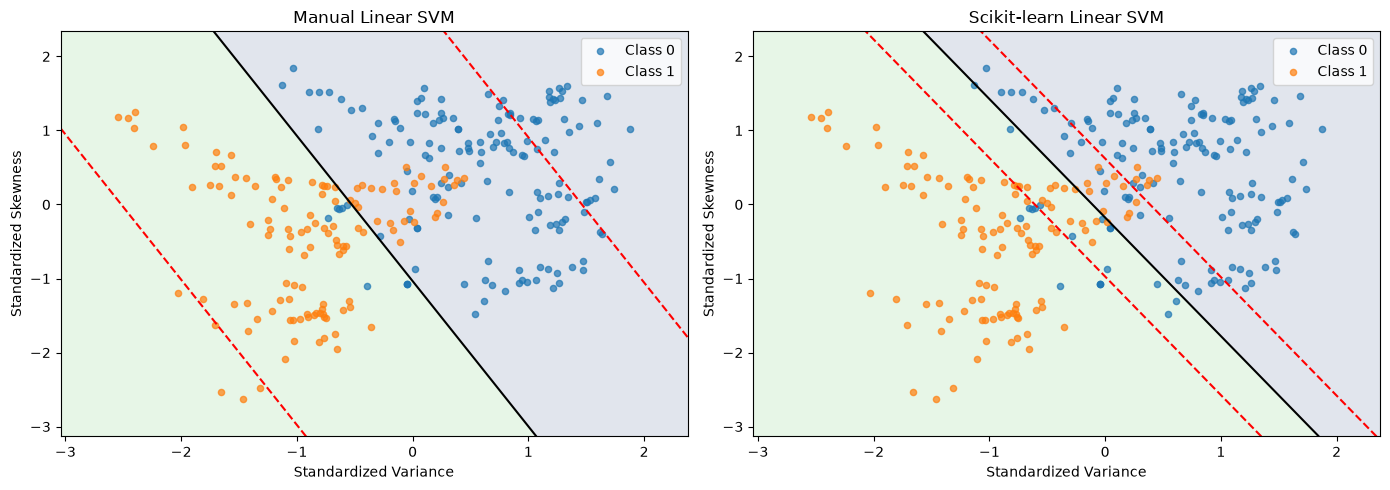

In [31]:

sklearn_svm = SVC(
    kernel="linear",
    C=1.0
)

sk_svm_train_start = time.perf_counter()
sklearn_svm.fit(X_train_svm, y_train_svm)
sk_svm_train_time = time.perf_counter() - sk_svm_train_start

sk_svm_predict_start = time.perf_counter()
y_pred_sklearn_svm = sklearn_svm.predict(X_test_svm)
sk_svm_predict_time = time.perf_counter() - sk_svm_predict_start

# Convert -1/+1 predictions back to 0/1
y_pred_sklearn_svm = np.where(y_pred_sklearn_svm == 1, 1, 0)

svm_comparison = pd.DataFrame({
    "Model": ["Manual Linear SVM", "Scikit-learn Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_manual_svm),
        accuracy_score(y_test, y_pred_sklearn_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_manual_svm, zero_division=0),
        precision_score(y_test, y_pred_sklearn_svm, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_manual_svm, zero_division=0),
        recall_score(y_test, y_pred_sklearn_svm, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_manual_svm, zero_division=0),
        f1_score(y_test, y_pred_sklearn_svm, zero_division=0)
    ],
    "Training Time (s)": [
        svm_train_time, sk_svm_train_time
    ],
    "Prediction Time (s)": [
        svm_predict_time, sk_svm_predict_time
    ]
})

display(svm_comparison.round(4))

# Compare both models' decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], manual_svm, "Manual Linear SVM"),
    (axes[1], sklearn_svm, "Scikit-learn Linear SVM")
]:
    scores = model.decision_function(svm_grid).reshape(svm_xx.shape)

    ax.contourf(
        svm_xx, svm_yy, scores,
        levels=[-100, 0, 100],
        alpha=0.15
    )

    ax.contour(
        svm_xx, svm_yy, scores,
        levels=[-1, 0, 1],
        colors=["red", "black", "red"],
        linestyles=["--", "-", "--"]
    )

    for class_label, svm_label in [(0, -1), (1, 1)]:
        mask = y_test_svm == svm_label
        ax.scatter(
            X_test_svm[mask, 0],
            X_test_svm[mask, 1],
            label=f"Class {class_label}",
            s=20,
            alpha=0.7
        )

    ax.set_xlabel("Standardized Variance")
    ax.set_ylabel("Standardized Skewness")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()



### 18. Effect of Regularization Parameter C

The regularization parameter C controls the trade-off between a large margin and hinge-loss penalties. Compare several C values while keeping the learning rate and number of iterations fixed.


In [32]:

C_values = [0.1, 1.0, 10.0]
C_results = []

for C_value in C_values:
    model = ManualLinearSVM(
        C=C_value,
        learning_rate=0.001,
        n_iterations=5000
    )

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_svm)

    C_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Training Time (s)": train_time,
        "Weight Norm": np.linalg.norm(model.weights)
    })

C_results_df = pd.DataFrame(C_results)
display(C_results_df.round(4))


,C,Accuracy,Precision,Recall,F1-score,Training Time (s),Weight Norm
0,0.1,0.8582,0.9770,0.6967,0.8134,0.5333,0.0834
1,1.0,0.8655,0.9126,0.7705,0.8356,0.5110,0.5640
2,10.0,0.8873,0.8957,0.8443,0.8692,0.4165,1.2178



### 19. Effect of Learning Rate

Compare different learning rates while keeping C = 1 and the number of iterations fixed. Observe how the learning rate affects convergence and predictive performance.


In [33]:

learning_rates = [0.0005, 0.001, 0.005]
learning_rate_results = []

for lr in learning_rates:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=lr,
        n_iterations=5000
    )

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_svm)

    learning_rate_results.append({
        "Learning Rate": lr,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Training Time (s)": train_time,
        "Final Objective": model.loss_history[-1]
    })

learning_rate_results_df = pd.DataFrame(learning_rate_results)
display(learning_rate_results_df.round(4))


,Learning Rate,Accuracy,Precision,Recall,F1-score,Training Time (s),Final Objective
0,0.0005,0.8727,0.8991,0.8033,0.8485,0.5350,0.6884
1,0.0010,0.8655,0.9126,0.7705,0.8356,0.5277,0.6869
2,0.0050,0.8655,0.9208,0.7623,0.8341,0.5447,0.6868



### 20. Effect of Number of Iterations

Compare the model using different iteration counts while keeping C = 1 and the learning rate fixed. More iterations can improve convergence, although gains may diminish once the objective stabilizes.


In [34]:

iteration_values = [1000, 3000, 5000, 10000]
iteration_results = []

for n_iter in iteration_values:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=0.001,
        n_iterations=n_iter
    )

    start = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_svm)

    iteration_results.append({
        "Iterations": n_iter,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Training Time (s)": train_time,
        "Final Objective": model.loss_history[-1]
    })

iteration_results_df = pd.DataFrame(iteration_results)
display(iteration_results_df.round(4))


,Iterations,Accuracy,Precision,Recall,F1-score,Training Time (s),Final Objective
0,1000,0.8873,0.8957,0.8443,0.8692,0.1202,0.7020
1,3000,0.8727,0.9065,0.7951,0.8472,0.3575,0.6878
2,5000,0.8655,0.9126,0.7705,0.8356,0.5389,0.6869
3,10000,0.8655,0.9208,0.7623,0.8341,1.0850,0.6868



## Part C: Kernel SVM and Nonlinear Decision Boundaries

### 21. Generating a Nonlinear Dataset

Generate a two-dimensional dataset with two interleaving moon-shaped classes. Split it into training and testing sets, and standardize the features using statistics from the training set only.


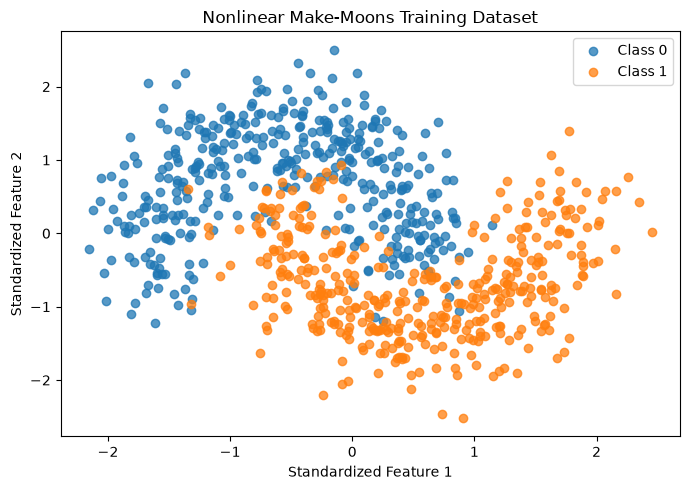

Training set: (800, 2)
Testing set: (200, 2)


In [35]:

# Generate a nonlinear two-class dataset
X_moons, y_moons = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.20,
        random_state=42,
        stratify=y_moons
    )
)

# Standardize using training data only
moons_mean = X_moons_train.mean(axis=0)
moons_std = X_moons_train.std(axis=0)
moons_std[moons_std == 0] = 1.0

X_moons_train_scaled = (X_moons_train - moons_mean) / moons_std
X_moons_test_scaled = (X_moons_test - moons_mean) / moons_std

plt.figure(figsize=(7, 5))

for class_label in np.unique(y_moons_train):
    mask = y_moons_train == class_label
    plt.scatter(
        X_moons_train_scaled[mask, 0],
        X_moons_train_scaled[mask, 1],
        label=f"Class {class_label}",
        alpha=0.75
    )

plt.title("Nonlinear Make-Moons Training Dataset")
plt.xlabel("Standardized Feature 1")
plt.ylabel("Standardized Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print("Training set:", X_moons_train_scaled.shape)
print("Testing set:", X_moons_test_scaled.shape)



### 22. Comparing Linear, Polynomial and RBF Kernels

Train three Scikit-learn SVM classifiers using linear, polynomial, and radial basis function (RBF) kernels.

The linear kernel produces a straight decision boundary. Polynomial and RBF kernels can represent nonlinear boundaries.


In [36]:

kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial (degree 3)": SVC(
        kernel="poly", degree=3, C=1.0, gamma="scale"
    ),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

kernel_results = []
kernel_predictions = {}

for kernel_name, model in kernel_models.items():
    start = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_moons_test_scaled)
    predict_time = time.perf_counter() - start

    kernel_predictions[kernel_name] = predictions

    kernel_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_moons_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    })

kernel_results_df = pd.DataFrame(kernel_results)
display(kernel_results_df.round(4))


,Kernel,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Linear,0.915,0.9368,0.89,0.9128,0.0092,0.0015
1,Polynomial (degree 3),0.905,0.9010,0.91,0.9055,0.0061,0.0011
2,RBF,0.965,0.9604,0.97,0.9652,0.0060,0.0035



### 23. Visualizing Kernel Decision Boundaries

Plot the decision regions learned by each kernel. Compare the linear boundary with the curved boundaries produced by the polynomial and RBF kernels.


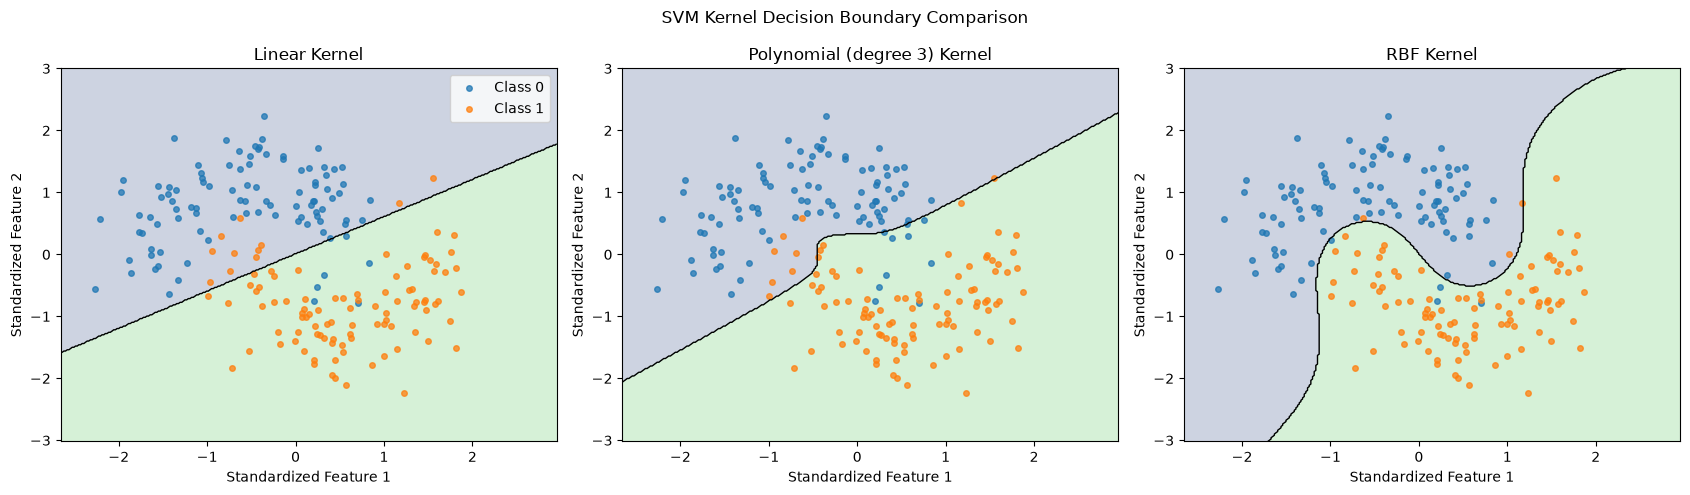

In [37]:

moon_x_min = X_moons_train_scaled[:, 0].min() - 0.5
moon_x_max = X_moons_train_scaled[:, 0].max() + 0.5
moon_y_min = X_moons_train_scaled[:, 1].min() - 0.5
moon_y_max = X_moons_train_scaled[:, 1].max() + 0.5

moon_xx, moon_yy = np.meshgrid(
    np.linspace(moon_x_min, moon_x_max, 300),
    np.linspace(moon_y_min, moon_y_max, 300)
)

moon_grid = np.c_[moon_xx.ravel(), moon_yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (kernel_name, model) in zip(
    axes, kernel_models.items()
):
    grid_predictions = model.predict(moon_grid).reshape(
        moon_xx.shape
    )

    ax.contourf(
        moon_xx,
        moon_yy,
        grid_predictions,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.25
    )

    ax.contour(
        moon_xx,
        moon_yy,
        grid_predictions,
        levels=[0.5],
        colors="black",
        linewidths=1
    )

    for class_label in np.unique(y_moons_test):
        mask = y_moons_test == class_label
        ax.scatter(
            X_moons_test_scaled[mask, 0],
            X_moons_test_scaled[mask, 1],
            label=f"Class {class_label}",
            s=16,
            alpha=0.75
        )

    ax.set_title(f"{kernel_name} Kernel")
    ax.set_xlabel("Standardized Feature 1")
    ax.set_ylabel("Standardized Feature 2")

axes[0].legend()
plt.suptitle("SVM Kernel Decision Boundary Comparison")
plt.tight_layout()
plt.show()



### 24. Effect of Regularization on the RBF Kernel

Evaluate the RBF SVM with different values of C while keeping gamma fixed at "scale". Compare the resulting test performance.


In [38]:

rbf_C_results = []

for C_value in [0.1, 1.0, 10.0, 100.0]:
    model = SVC(
        kernel="rbf",
        C=C_value,
        gamma="scale"
    )

    start = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_moons_test_scaled)

    rbf_C_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_moons_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Training Time (s)": train_time
    })

rbf_C_results_df = pd.DataFrame(rbf_C_results)
display(rbf_C_results_df.round(4))


,C,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,0.1,0.950,0.9500,0.95,0.9500,0.0105
1,1.0,0.965,0.9604,0.97,0.9652,0.0056
2,10.0,0.975,0.9612,0.99,0.9754,0.0072
3,100.0,0.975,0.9612,0.99,0.9754,0.0111



## Part D: Final Model Comparison Using All Four Features

### 25. Training Decision Tree Models

Train the manual and Scikit-learn Decision Trees using all four banknote features. Keep the same train-test split, Gini criterion, and maximum depth of 5.


In [39]:

# Manual Decision Tree using all four features
final_manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

start = time.perf_counter()
final_manual_tree.fit(X_train_all, y_train)
final_manual_tree_train_time = time.perf_counter() - start

start = time.perf_counter()
final_manual_tree_pred = final_manual_tree.predict(X_test_all)
final_manual_tree_predict_time = time.perf_counter() - start


# Scikit-learn Decision Tree using all four features
final_sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

start = time.perf_counter()
final_sklearn_tree.fit(X_train_all, y_train)
final_sklearn_tree_train_time = time.perf_counter() - start

start = time.perf_counter()
final_sklearn_tree_pred = final_sklearn_tree.predict(X_test_all)
final_sklearn_tree_predict_time = time.perf_counter() - start


print("Manual Decision Tree accuracy:",
      round(accuracy_score(y_test, final_manual_tree_pred), 4))

print("Scikit-learn Decision Tree accuracy:",
      round(accuracy_score(y_test, final_sklearn_tree_pred), 4))

print("Prediction agreement:",
      round(np.mean(final_manual_tree_pred == final_sklearn_tree_pred), 4))


Manual Decision Tree accuracy: 0.9927
Scikit-learn Decision Tree accuracy: 0.9927
Prediction agreement: 1.0



### 26. Training Linear and Kernel SVM Models

Train the manual Linear SVM and Scikit-learn Linear, Polynomial and RBF SVMs using all four features. Standardize the features using training-set statistics only.

For the manual SVM, use the previously tested settings C = 1, learning rate = 0.001, and 5,000 iterations.


In [40]:

# Standardize all four features using training statistics only
final_svm_mean = X_train_all.mean(axis=0)
final_svm_std = X_train_all.std(axis=0)
final_svm_std[final_svm_std == 0] = 1.0

X_train_all_svm = (X_train_all - final_svm_mean) / final_svm_std
X_test_all_svm = (X_test_all - final_svm_mean) / final_svm_std

# Encode labels as -1 and +1 for the manual SVM
y_train_all_svm = np.where(y_train == 1, 1, -1)

# Manual Linear SVM
final_manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.001,
    n_iterations=5000
)

start = time.perf_counter()
final_manual_svm.fit(X_train_all_svm, y_train_all_svm)
final_manual_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
final_manual_svm_pred = final_manual_svm.predict(X_test_all_svm)
final_manual_svm_predict_time = time.perf_counter() - start


# Scikit-learn SVM models
final_sklearn_svms = {
    "Scikit-learn Linear SVM": SVC(kernel="linear", C=1.0),
    "Polynomial SVM (degree 3)": SVC(
        kernel="poly", degree=3, C=1.0, gamma="scale"
    ),
    "RBF SVM": SVC(kernel="rbf", C=1.0, gamma="scale")
}

final_svm_predictions = {}
final_svm_times = {}

for model_name, model in final_sklearn_svms.items():
    start = time.perf_counter()
    model.fit(X_train_all_svm, y_train)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test_all_svm)
    predict_time = time.perf_counter() - start

    final_svm_predictions[model_name] = predictions
    final_svm_times[model_name] = {
        "train": fit_time,
        "predict": predict_time
    }

print("All four-feature SVM models trained successfully.")
print("Training shape:", X_train_all_svm.shape)
print("Testing shape:", X_test_all_svm.shape)


All four-feature SVM models trained successfully.
Training shape: (1097, 4)
Testing shape: (275, 4)



### 27. Final Performance Comparison

Compare all models using accuracy, precision, recall, F1-score, training time, and prediction time. All metrics are calculated on the same held-out test set of 275 samples.


In [41]:

final_model_results = []

def add_final_result(
    model_name, y_true, y_pred, train_time, predict_time
):
    final_model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    })


# Decision Tree results
add_final_result(
    "Manual Decision Tree",
    y_test,
    final_manual_tree_pred,
    final_manual_tree_train_time,
    final_manual_tree_predict_time
)

add_final_result(
    "Scikit-learn Decision Tree",
    y_test,
    final_sklearn_tree_pred,
    final_sklearn_tree_train_time,
    final_sklearn_tree_predict_time
)

# Manual SVM result
add_final_result(
    "Manual Linear SVM",
    y_test,
    final_manual_svm_pred,
    final_manual_svm_train_time,
    final_manual_svm_predict_time
)

# Scikit-learn SVM results
for model_name, predictions in final_svm_predictions.items():
    add_final_result(
        model_name,
        y_test,
        predictions,
        final_svm_times[model_name]["train"],
        final_svm_times[model_name]["predict"]
    )

final_comparison_df = pd.DataFrame(final_model_results)

display(
    final_comparison_df
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

best_model_row = final_comparison_df.loc[
    final_comparison_df["F1-score"].idxmax()
]

print("\nBest model by F1-score:", best_model_row["Model"])
print("Best F1-score:", round(best_model_row["F1-score"], 4))


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0050,0.0022
1,Manual Decision Tree,0.9927,0.9839,1.0000,0.9919,1.1043,0.0005
2,Scikit-learn Decision Tree,0.9927,0.9839,1.0000,0.9919,0.0047,0.0004
3,Polynomial SVM (degree 3),0.9818,0.9606,1.0000,0.9799,0.0086,0.0016
4,Scikit-learn Linear SVM,0.9745,0.9457,1.0000,0.9721,0.0090,0.0007
5,Manual Linear SVM,0.8800,0.9238,0.7951,0.8546,0.5537,0.0001



Best model by F1-score: RBF SVM
Best F1-score: 1.0



### 28. Visual Comparison of Model Performance

Plot accuracy and F1-score for all models using the four-feature test results.


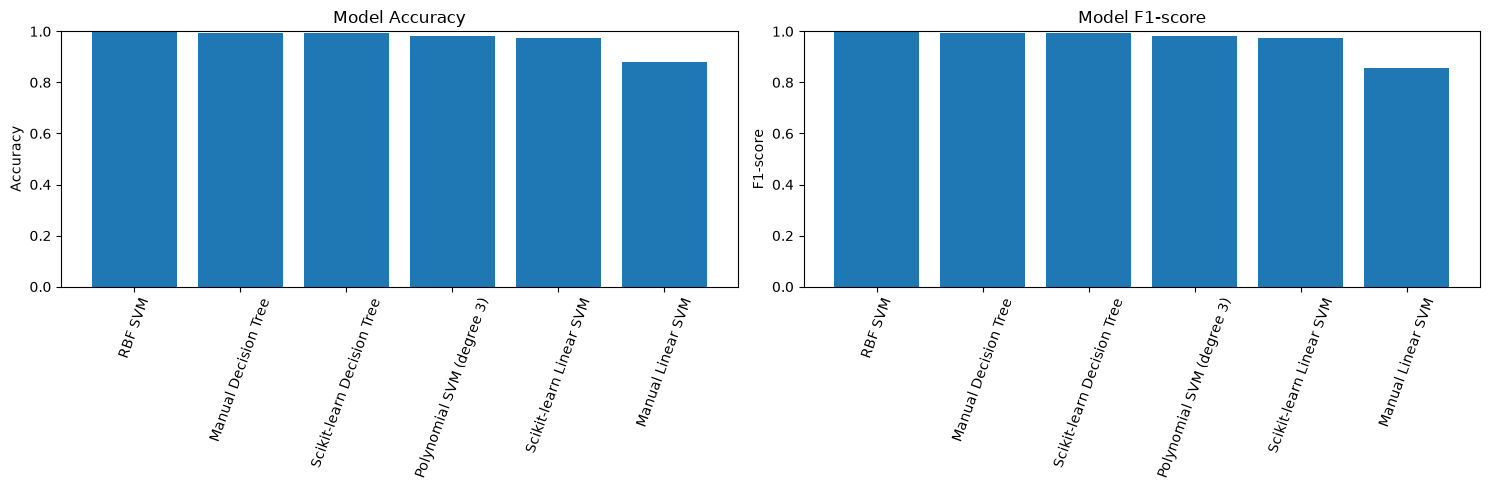

In [42]:

plot_df = final_comparison_df.sort_values(
    "F1-score", ascending=False
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(plot_df["Model"], plot_df["Accuracy"])
axes[0].set_title("Model Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=70)

axes[1].bar(plot_df["Model"], plot_df["F1-score"])
axes[1].set_title("Model F1-score")
axes[1].set_ylabel("F1-score")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()



### 30. Confusion Matrix for the Best Model

Visualize the confusion matrix of the Scikit-learn RBF SVM using the held-out banknote test set.


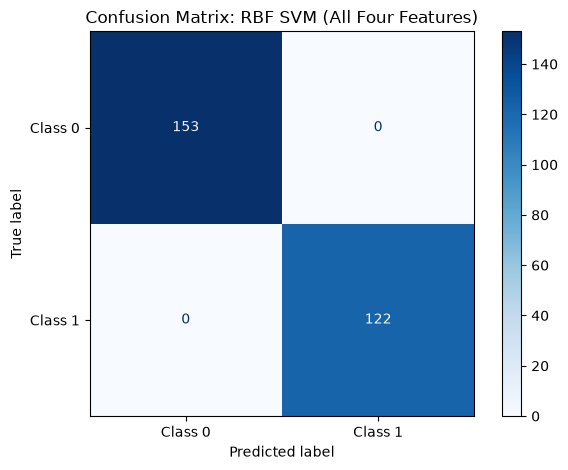

Correct predictions: 275
Total test samples: 275
Misclassified samples: 0


In [43]:

from sklearn.metrics import ConfusionMatrixDisplay

best_final_svm = final_sklearn_svms["RBF SVM"]

ConfusionMatrixDisplay.from_estimator(
    best_final_svm,
    X_test_all_svm,
    y_test,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues"
)

plt.title("Confusion Matrix: RBF SVM (All Four Features)")
plt.tight_layout()
plt.show()

print("Correct predictions:",
      int(np.sum(final_svm_predictions["RBF SVM"] == y_test)))

print("Total test samples:", len(y_test))
print("Misclassified samples:",
      int(np.sum(final_svm_predictions["RBF SVM"] != y_test)))
